<a href="https://colab.research.google.com/github/A01178685/clase_lol_10/blob/main/Presentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mexico’s Human Capital Index Comparison


[Initial setup](#scrollTo=vseoY8IkIjKN)

[Description of Data Set / Variables](#scrollTo=Fi8f_JvDJY-C&line)

[RQ1: How did Mexico’s HCI change from 2010 to 2020?](#scrollTo=HCIRQ1_2026)
   - Area plot

[RQ2: How did Mexico’s HCI change compare with the region and world?](#scrollTo=HCIRQ2_2026)
   - Horizontal bar plot

[RQ3: Where does Mexico stand in the country HCI distribution?](#scrollTo=UR1cwwIHIPif&line)
   - Histogram

[RQ4: How do female and male HCI distributions compare across countries?](#scrollTo=fDZtHk_gLlaZ&line)
   - Box plot

[RQ5: How do Mexico’s two schooling measures compare?](#scrollTo=efS4ptxXMGu-&line)
   - Vertical bar plot

[RQ6: How did learning-adjusted schooling change across areas?](#scrollTo=VSC1s08qMZke&line)
   - Line plot

[RQ7: How many countries exceeded Mexico’s adult survival rate?](#scrollTo=-pj7K-XdMw5r&line)
   - Pie chart

[RQ8: How are learning-adjusted years of school associated with HCI across countries in 2020?](#scrollTo=JBWLoaRqNKDk&line)
   - Line Regression

[Final Conclusions](#scrollTo=Ykq3WWSelT2G&line)

## 1. initial setup



In [19]:
file_path = 'WB_HCI.csv'
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv(file_path)
df.head()

,STRUCTURE,STRUCTURE_ID,ACTION,FREQ,FREQ_LABEL,REF_AREA,REF_AREA_LABEL,INDICATOR,INDICATOR_LABEL,SEX,...,TIME_PERIOD,OBS_VALUE,DATABASE_ID,DATABASE_ID_LABEL,UNIT_MULT,UNIT_MULT_LABEL,UNIT_TYPE,UNIT_TYPE_LABEL,TIME_FORMAT,TIME_FORMAT_LABEL
0,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,WLD,World,WB_HCI_ASR,Adult Survival Rate,_T,...,2010,0.840845,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
1,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,WLD,World,WB_HCI_ASR,Adult Survival Rate,_T,...,2018,0.846043,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
2,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,WLD,World,WB_HCI_ASR,Adult Survival Rate,_T,...,2020,0.848294,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
3,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,EAS,East Asia & Pacific,WB_HCI_ASR,Adult Survival Rate,_T,...,2010,0.900628,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
4,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,EAS,East Asia & Pacific,WB_HCI_ASR,Adult Survival Rate,_T,...,2018,0.861863,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY


##[ Description of the dataset](#scrollTo=HCINAV2026&line)



**Purpose:** Examine Mexico’s Human Capital Index over time, compare it with other areas, and explore schooling, adult survival, and HCI across countries.

`WB_HCI.csv` contains 15,039 rows and 33 columns of World Bank human capital data for 186 geographic areas. Each row records one indicator for an area, year, and sex category. The available years are 2010, 2018, and 2020. Some areas, such as World and Latin America & Caribbean, are aggregates; others are individual countries.

**Variables used:**

- REF_AREA — categorical: Area code used to identify countries and exclude aggregate areas.
- REF_AREA_LABEL — categorical: Name of the country or aggregate area.
- TIME_PERIOD — numerical, discrete: Observation year.
- SEX_LABEL — categorical: Total, Female, or Male.
- INDICATOR — categorical: Code identifying HCI, expected years of school, learning-adjusted years of school, or adult survival rate.
- INDICATOR_LABEL — categorical text: Full indicator name used in the schooling figure.
- OBS_VALUE — numerical: Recorded indicator value. HCI ranges from 0 to 1, schooling is measured in years, and adult survival is a proportion.
- LAYS - means Learning Adjusted Years of School. It estimates how many years of schooling students effectively receive after accounting for how much they learn. For example, 10 years in school might equal 7 LAYS if learning outcomes are lower
HCI means Human Capital Index. It summarizes expected health and education outcomes; a higher score indicates greater potential human capital.

In [20]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'ACTION', 'FREQ', 'FREQ_LABEL', 'REF_AREA',
       'REF_AREA_LABEL', 'INDICATOR', 'INDICATOR_LABEL', 'SEX', 'SEX_LABEL',
       'AGE', 'AGE_LABEL', 'URBANISATION', 'URBANISATION_LABEL',
       'UNIT_MEASURE', 'UNIT_MEASURE_LABEL', 'COMP_BREAKDOWN_1',
       'COMP_BREAKDOWN_1_LABEL', 'COMP_BREAKDOWN_2', 'COMP_BREAKDOWN_2_LABEL',
       'COMP_BREAKDOWN_3', 'COMP_BREAKDOWN_3_LABEL', 'TIME_PERIOD',
       'OBS_VALUE', 'DATABASE_ID', 'DATABASE_ID_LABEL', 'UNIT_MULT',
       'UNIT_MULT_LABEL', 'UNIT_TYPE', 'UNIT_TYPE_LABEL', 'TIME_FORMAT',
       'TIME_FORMAT_LABEL'],
      dtype='object')

## Eight-study analytical roadmap

| Study | Research question | Figure | Main finding |
|---|---|---|---|
| 1 | How did Mexico’s HCI change? | Area plot | It rose 0.024 points from 2010 to 2020. |
| 2 | How did that change compare with the region and World? | Horizontal bar plot | Mexico gained 0.024, the region gained 0.010, and World fell 0.030. |
| 3 | Where does Mexico stand in the 2020 country distribution? | Histogram | Mexico’s 0.613 exceeded the country median of 0.564. |
| 4 | How do female and male HCI scores vary across countries? | Box plot | Female median: 0.600; male median: 0.559 among 153 countries. |
| 5 | How do Mexico’s schooling measures compare? | Vertical bar plot | Expected years exceeded learning-adjusted years by 4.000 in 2020. |
| 6 | How did learning-adjusted schooling change across areas? | Line plot | Mexico gained 0.320 years while the World entry declined. |
| 7 | What share of other countries exceeded Mexico’s adult survival rate? | Pie chart | 85 of 173 countries (49.1%) had a higher rate. |
| 8 | How are schooling and adult survival associated with HCI? | Regression and scatterplot | In-sample R² = 0.986; fitted Mexico HCI ≈ 0.614. |

##[RQ1: How did Mexico’s HCI change from 2010 to 2020?](#scrollTo=HCINAV2026)


**Study:** Select Mexico’s three available HCI scores, calculate the change from 2010 to 2020, and show an area plot.

TIME_PERIOD
2010    0.589119
2018    0.611657
2020    0.612950
Name: OBS_VALUE, dtype: float64
Increase, 2010–2020 (HCI points): 0.023831069469451904


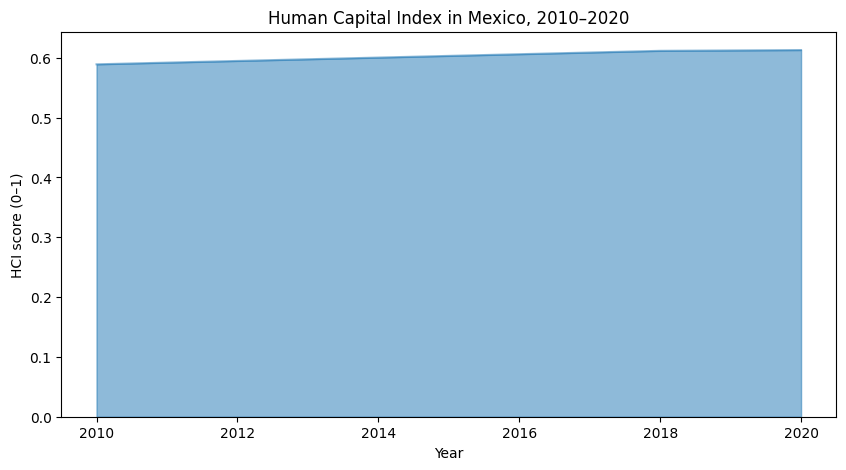

In [21]:
hci = df[df['INDICATOR'] == 'WB_HCI_HCI']
hci = hci[hci['SEX_LABEL'] == 'Total']

mexico = hci[hci['REF_AREA_LABEL'] == 'Mexico'].sort_values(['TIME_PERIOD']).set_index('TIME_PERIOD')['OBS_VALUE']
print(mexico)

aumento = mexico.loc[2020] - mexico.loc[2010]
print('Increase, 2010–2020 (HCI points):', aumento)

mexico.plot(kind='area', stacked=False, alpha=0.5, figsize=(10, 5))
plt.title('Human Capital Index in Mexico, 2010–2020')
plt.xlabel('Year')
plt.ylabel('HCI score (0–1)')
plt.show()

### Insight

Mexico’s HCI rose from 0.589 in 2010 to 0.613 in 2020, an increase of approximately 0.024 index points.




##[RQ2: How did Mexico’s HCI change compare with regional and world changes?](#scrollTo=HCINAV2026)


**Study:** For each area, subtract its **2010 HCI score from its 2020 score**. A horizontal bar plot compares Mexico with the Latin America & Caribbean and World aggregate entries. A bar left of zero means a decrease in the score.

Change from 2010 to 2020 (HCI points):
REF_AREA_LABEL
World                       -0.030000
Latin America & Caribbean    0.010000
Mexico                       0.023831
Name: OBS_VALUE, dtype: float64


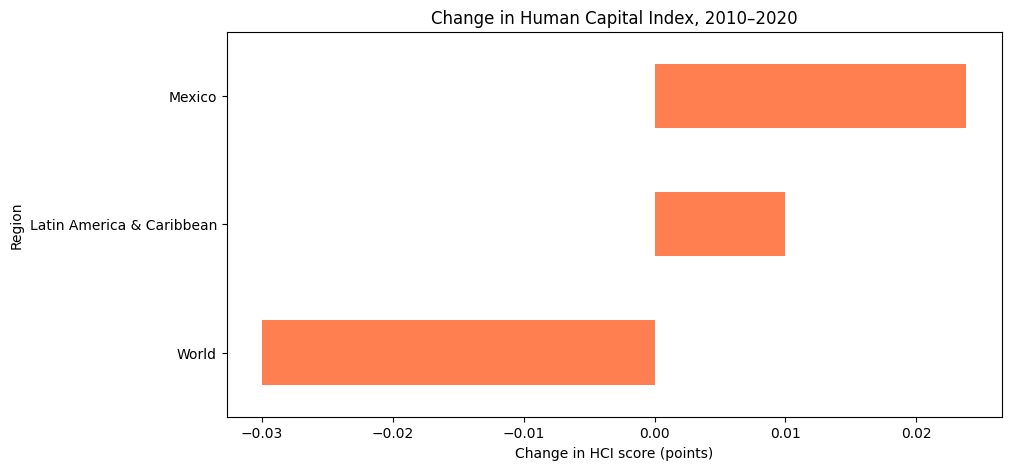

In [22]:
hci_inicio = hci[hci['TIME_PERIOD'] == 2010].set_index('REF_AREA_LABEL')
hci_final = hci[hci['TIME_PERIOD'] == 2020].set_index('REF_AREA_LABEL')
areas = ['World', 'Latin America & Caribbean', 'Mexico']
cambio = hci_final.loc[areas, 'OBS_VALUE'] - hci_inicio.loc[areas, 'OBS_VALUE']
print('Change from 2010 to 2020 (HCI points):')
print(cambio)

cambio.plot(kind='barh', figsize=(10, 5), color='coral')
plt.title('Change in Human Capital Index, 2010–2020')
plt.xlabel('Change in HCI score (points)')
plt.ylabel('Region')
plt.show()

### Insights
From 2010 to 2020, Mexico gained 0.024 HCI points and Latin America & Caribbean gained 0.010, while the World aggregate fell 0.030 based on given dataset.


## [RQ3: Where does Mexico stand in the distribution of country HCI scores in 2020?](#scrollTo=HCINAV2026)

Study: Filter to 2020, Total, and individual countries. A histogram shows how many countries fall in each HCI range. Mark Mexico’s score so the comparison is visible in the figure.

Countries: 174
Country median: 0.5638292729854584
Mexico: 0.6129498481750488
Countries below Mexico: 113


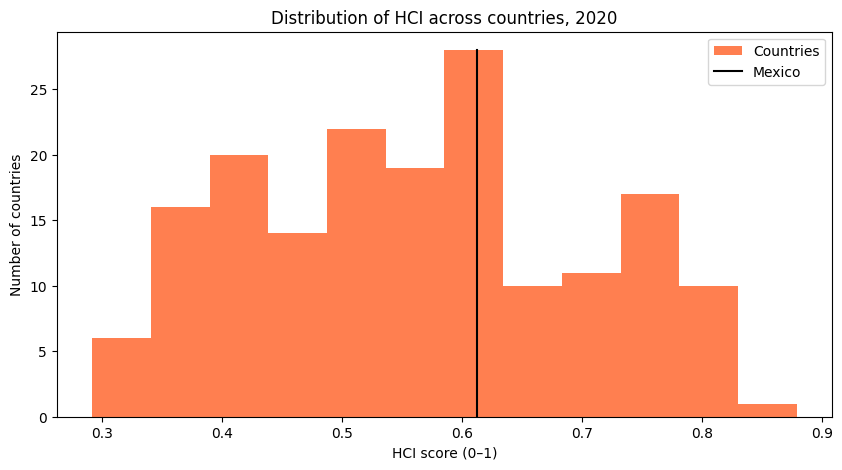

In [23]:
agregados = ['WLD', 'EAS', 'ECS', 'HIC', 'LCN', 'LIC', 'LMC',
             'MEA', 'NAC', 'SAS', 'SSF', 'UMC']
paises_2020 = df[df['TIME_PERIOD'] == 2020]
paises_2020 = paises_2020[paises_2020['SEX_LABEL'] == 'Total']
paises_2020 = paises_2020[~paises_2020['REF_AREA'].isin(agregados)]
hci_2020 = paises_2020[paises_2020['INDICATOR'] == 'WB_HCI_HCI'].set_index('REF_AREA_LABEL')['OBS_VALUE'].dropna()
hci_2020.name = 'Countries'
mexico_2020 = hci_2020.loc['Mexico']
conteos, intervalos = np.histogram(hci_2020, bins=12)
print('Countries:', len(hci_2020))
print('Country median:', hci_2020.median())
print('Mexico:', mexico_2020)
print('Countries below Mexico:', (hci_2020 < mexico_2020).sum())

hci_2020.plot(kind='hist', bins=12, figsize=(10, 5), color='coral')
plt.plot([mexico_2020, mexico_2020], [0, max(conteos)], color='black', label='Mexico')
plt.title('Distribution of HCI across countries, 2020')
plt.xlabel('HCI score (0–1)')
plt.ylabel('Number of countries')
plt.legend()
plt.show()


##Insight
Among 174 countries, the median 2020 HCI was 0.564. Mexico’s 0.613 was above that median; 113 countries had lower scores. Each histogram bar counts countries, not people.

## [RQ4: How do female and male HCI scores vary across countries in 2020?](#scrollTo=HCINAV2026)

Study: Compare box plots for Male and Female country HCI scores. Use only the countries with both sex-specific scores so the groups refer to the same set of places.

Countries with both values: 153
Medians:
Male      0.559381
Female    0.599642
dtype: float64


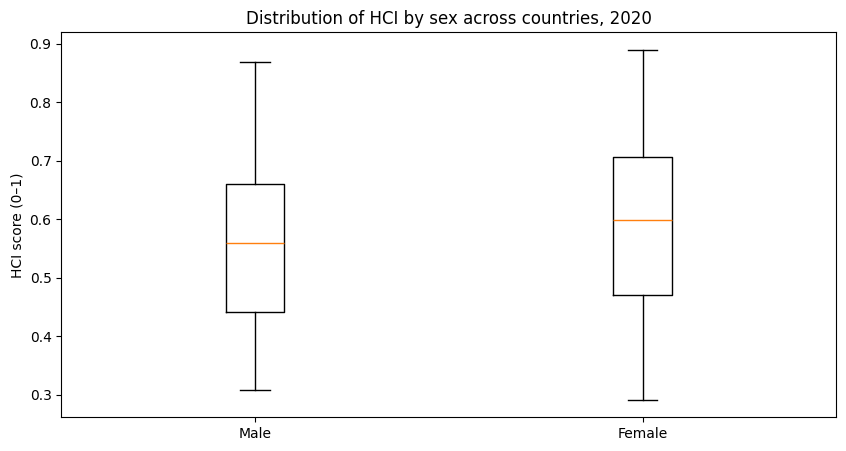

In [24]:
sexos_2020 = df[df['INDICATOR'] == 'WB_HCI_HCI']
sexos_2020 = sexos_2020[sexos_2020['TIME_PERIOD'] == 2020]
sexos_2020 = sexos_2020[~sexos_2020['REF_AREA'].isin(agregados)]
hombres = sexos_2020[sexos_2020['SEX_LABEL'] == 'Male'].set_index('REF_AREA_LABEL')['OBS_VALUE']
mujeres = sexos_2020[sexos_2020['SEX_LABEL'] == 'Female'].set_index('REF_AREA_LABEL')['OBS_VALUE']
comparacion_sexo = pd.DataFrame({'Male': hombres, 'Female': mujeres}).dropna()
print('Countries with both values:', len(comparacion_sexo))
print('Medians:')
print(comparacion_sexo.median())

plt.figure(figsize=(10, 5))
plt.boxplot([comparacion_sexo['Male'], comparacion_sexo['Female']])
plt.xticks([1, 2], ['Male', 'Female'])
plt.title('Distribution of HCI by sex across countries, 2020')
plt.ylabel('HCI score (0–1)')
plt.show()


##Insight
Across the 153 countries with both values, the female median was 0.600 and the male median was 0.559. These boxes summarize countries, not the number of women or men; their medians alone do not show the difference within every country.

## [RQ5: How did expected and learning-adjusted years of school compare in Mexico in 2020?](#scrollTo=HCINAV2026)

Study: Compare two schooling measures in years for Mexico in 2020. Vertical bars make their approximately four-year difference easy to see.

INDICATOR_LABEL
Expected Years of School             12.824008
Learning-Adjusted Years of School     8.824254
Name: OBS_VALUE, dtype: float64


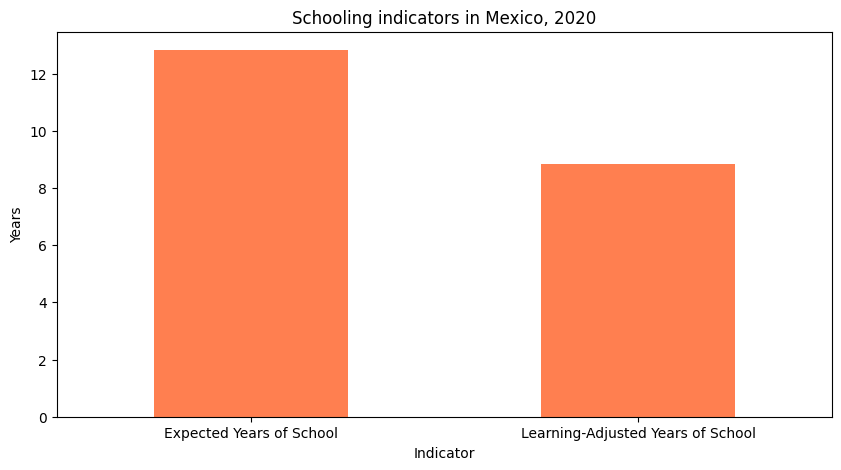

In [25]:
escuela = df[df['REF_AREA_LABEL'] == 'Mexico']
escuela = escuela[escuela['SEX_LABEL'] == 'Total']
escuela = escuela[escuela['TIME_PERIOD'] == 2020]
escuela = escuela.set_index('INDICATOR_LABEL')
indicadores = ['Expected Years of School', 'Learning-Adjusted Years of School']
anios = escuela.loc[indicadores, 'OBS_VALUE']
print(anios)

anios.plot(kind='bar', figsize=(10, 5), color='coral')
plt.title('Schooling indicators in Mexico, 2020')
plt.xlabel('Indicator')
plt.ylabel('Years')
plt.xticks(rotation=0)
plt.show()


##Insight
Mexico recorded 12.824 expected years of school and 8.824 learning-adjusted years in 2020, a gap of about 4.000 years between the two measures. They are different indicators, not observed years of attendance for a particular person.

## [RQ6: How did learning-adjusted years of school change in Mexico, the region, and World?](#scrollTo=HCINAV2026)

Study: Select the three observed years for each area and draw a line for each. This shows whether *Mexicos* trend resembled the region and World aggregate trends; the dataset does not provide annual values between points.

               Mexico  Latin America & Caribbean     World
TIME_PERIOD                                               
2010         8.503864                   7.822436  8.523353
2018         8.812746                   7.786876  7.904103
2020         8.824254                   7.820240  7.813699


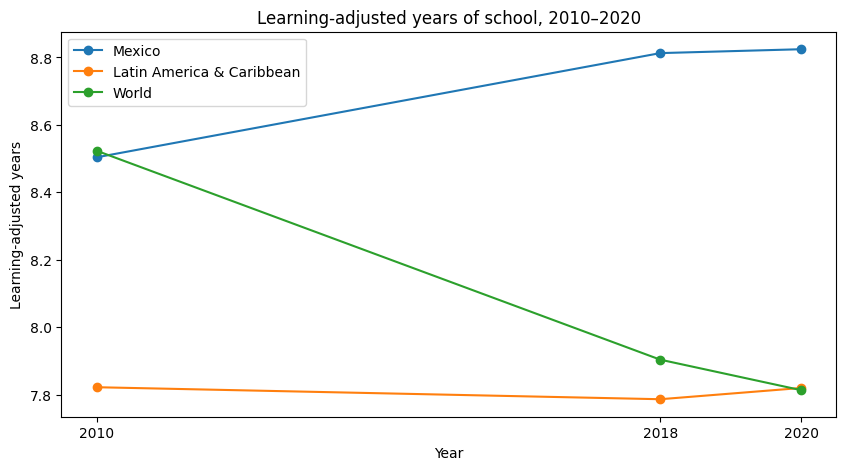

In [26]:
aprendizaje = df[df['INDICATOR'] == 'WB_HCI_LAYS']
aprendizaje = aprendizaje[aprendizaje['SEX_LABEL'] == 'Total']
series = {}
for area in ['Mexico', 'Latin America & Caribbean', 'World']:
    datos = aprendizaje[aprendizaje['REF_AREA_LABEL'] == area]
    series[area] = datos.sort_values('TIME_PERIOD').set_index('TIME_PERIOD')['OBS_VALUE']
comparacion_aprendizaje = pd.DataFrame(series)
print(comparacion_aprendizaje)

comparacion_aprendizaje.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Learning-adjusted years of school, 2010–2020')
plt.xlabel('Year')
plt.ylabel('Learning-adjusted years')
plt.xticks([2010, 2018, 2020])
plt.show()


##Insight
Mexico’s learning-adjusted schooling rose from 8.504 to 8.824 years, a gain of 0.320. The regional entry was almost unchanged (7.822 to 7.820), while the World entry declined from 8.523 to 7.814. Lines connect three observations, not annual measurements.

## [RQ7: What share of other countries had higher adult survival than Mexico in 2020?](#scrollTo=HCINAV2026)

Study: Use the adult survival rate for the Total category in 2020. Compare each other country’s rate with Mexico’s. The two slices count countries above Mexico and countries at or below Mexico, so together they represent all 173 other countries.

Mexico adult survival rate: 0.8614773750305176
Other countries: 173
Higher than Mexico    85
At or below Mexico    88
dtype: int64


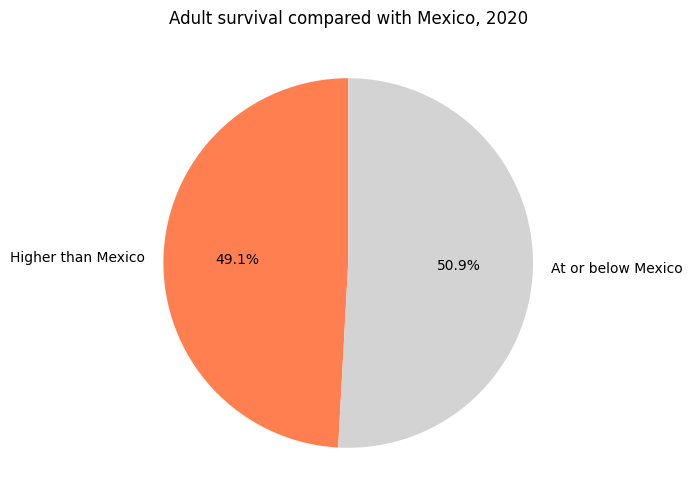

In [27]:
supervivencia_2020 = paises_2020[paises_2020['INDICATOR'] == 'WB_HCI_ASR'].set_index('REF_AREA_LABEL')['OBS_VALUE'].dropna()
tasa_mexico = supervivencia_2020.loc['Mexico']
otros_paises = supervivencia_2020.drop('Mexico')
conteos_supervivencia = pd.Series({
    'Higher than Mexico': (otros_paises > tasa_mexico).sum(),
    'At or below Mexico': (otros_paises <= tasa_mexico).sum()
})
print('Mexico adult survival rate:', tasa_mexico)
print('Other countries:', len(otros_paises))
print(conteos_supervivencia)

plt.figure(figsize=(8, 6))
plt.pie(conteos_supervivencia, labels=conteos_supervivencia.index,
        autopct='%1.1f%%', startangle=90, colors=['coral', 'lightgray'])
plt.title('Adult survival compared with Mexico, 2020')
plt.show()


##Insight
Of 173 other countries, 85 (49.1%) had a higher adult survival rate than Mexico in 2020; 88 (50.9%) were at or below Mexico. Each slice counts countries equally, regardless of population size.

## [RQ8: How are learning adjusted years of school associated with HCI across countries in 2020?](#scrollTo=HCINAV2026)

Study: Use a simple linear regression for 174 individual countries in 2020. HCI is the dependent variable and LAYS is the only independent variable. Exclude World, regional, and income-group aggregates. Report the regression summary, show each country’s actual and estimated HCI with its residual, and graph the observations with the regression line.



In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

file_path = 'WB_HCI.csv'
df = pd.read_csv(file_path)

agregados = ['WLD', 'EAS', 'ECS', 'HIC', 'LCN', 'LIC', 'LMC',
             'MEA', 'NAC', 'SAS', 'SSF', 'UMC']

datos_2020 = df[df['TIME_PERIOD'] == 2020]
datos_2020 = datos_2020[datos_2020['SEX_LABEL'] == 'Total']
datos_2020 = datos_2020[~datos_2020['REF_AREA'].isin(agregados)]

hci_pais = datos_2020[
    datos_2020['INDICATOR'] == 'WB_HCI_HCI'
].set_index('REF_AREA_LABEL')['OBS_VALUE']

lays_pais = datos_2020[
    datos_2020['INDICATOR'] == 'WB_HCI_LAYS'
].set_index('REF_AREA_LABEL')['OBS_VALUE']

reg = pd.DataFrame({'HCI': hci_pais, 'LAYS': lays_pais}).dropna()

reg_eqn = 'HCI ~ LAYS'
modelA = sm.OLS.from_formula(reg_eqn, data=reg).fit()
modelA.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    HCI   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.975
Method:                 Least Squares   F-statistic:                     6763.
Date:                Sat, 24 Oct 2026   Prob (F-statistic):          5.15e-140
Time:                        00:32:19   Log-Likelihood:                 418.47
No. Observations:                 174   AIC:                            -832.9
Df Residuals:                     172   BIC:                            -826.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1264      0.006     22.808      0.000       0.115       0.137
LAYS           0.0557      0.001     82.240      0.000       0.054       0.057
==============================================================================
Omnibus:                        4.961   Durbin-Watson:                   1.727
Prob(Omnibus):                  0.084   Jarque-Bera (JB):                5.191
Skew:                          -0.247   Prob(JB):                       0.0746
Kurtosis:                       3.687   Cond. No.                         27.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [29]:
study = [
    reg['LAYS'],
    reg['HCI'],
    modelA.fittedvalues.rename('Estimated HCI'),
    modelA.resid.rename('Residual')
]

pd.concat(study, axis=1)

,LAYS,HCI,Estimated HCI,Residual
REF_AREA_LABEL,,,,
Afghanistan,5.052838,0.400284,0.407634,-0.007350
Angola,4.234978,0.362405,0.362119,0.000286
Albania,8.953018,0.634251,0.624684,0.009567
United Arab Emirates,9.645997,0.673012,0.663249,0.009763
Argentina,8.411310,0.602145,0.594537,0.007607
...,...,...,...,...
Kosovo,7.870821,0.567332,0.564459,0.002873
"Yemen, Rep.",4.178761,0.372784,0.358991,0.013793
South Africa,5.603404,0.425453,0.438274,-0.012821


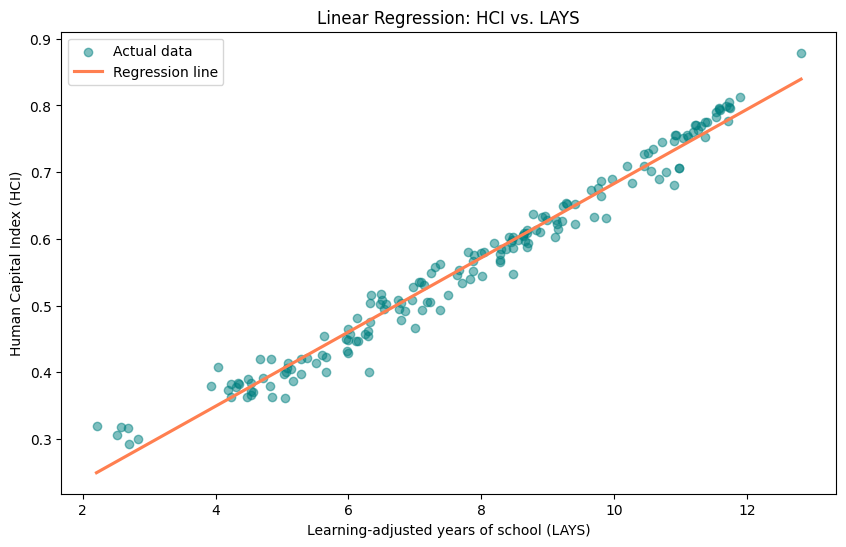

In [30]:
plt.figure(figsize=(10, 6))

ax = sns.regplot(
    x='LAYS', y='HCI', data=reg, ci=None,
    scatter_kws={'color': 'teal', 'alpha': 0.5},
    line_kws={'color': 'coral'}
)

ax.set(
    xlabel='Learning-adjusted years of school (LAYS)',
    ylabel='Human Capital Index (HCI)',
    title='Linear Regression: HCI vs. LAYS'
)

ax.collections[0].set_label('Actual data')
ax.lines[0].set_label('Regression line')
ax.legend()

plt.show()

## Results
The simple regression used 174 countries in 2020. Its estimated equation is HCI = 0.1264 + 0.0557 × LAYS, with R² ≈ 0.975. Mexico’s observed HCI was 0.613 and its estimated HCI was 0.618. Lesotho, Liberia, and Iraq had the largest absolute residuals.

## Insights
Countries with more learning-adjusted years of school generally have higher HCI scores. Each additional LAYS is associated with about 0.056 more HCI points in this model. Mexico lies close to the regression line. Because schooling contributes to HCI itself, this strong relationship does not establish causation.


## [Final conclusions](#scrollTo=HCINAV2026)

Mexico’s HCI rose by 0.024 points from 2010 to 2020, more than the regional increase of 0.010, while the World entry fell by 0.030. Mexico’s 2020 score of 0.613 was also above the median of the 174 individual countries (0.564). Across countries with sex-specific data, the female median (0.600) exceeded the male median (0.559); these medians do not describe Mexico’s own female–male difference.

Mexico had a 4.000-year gap between expected schooling (12.824 years) and learning-adjusted schooling (8.824 years) in 2020. Its LAYS nevertheless increased by 0.320 years since 2010. In adult survival, 85 of 173 other countries (49.1%) scored higher than Mexico. The simple regression shows a strong relationship between LAYS and HCI across countries (R² ≈ 0.975); Mexico’s estimated HCI of 0.618 is close to its observed 0.613.

The trends cover only three observed years. The regional and World figures are aggregates, while the country comparisons give each country equal weight. Because schooling contributes to HCI, the regression does not establish causation or predict future scores.